In [1]:
# Install KaggleHub
!pip install kagglehub[pandas-datasets]

import kagglehub
from kagglehub import KaggleDatasetAdapter

# File name
file_path = "insurance.csv"

# Load dataset
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "mirichoi0218/insurance",
    file_path,
)

# Display first 5 records
print("Dataset loaded successfully!")
print(df.head())

/tmp/ipykernel_6728/4107838313.py:11: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'insurance' dataset.
Dataset loaded successfully!
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [2]:
print(df.shape)
print(df.columns)
df.info()
print(df.describe())
print(df.isnull().sum())

(1338, 7)
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400

In [3]:
# 1.checking data set info
print("--- Dataset Info ---")
print(df.info())

# 2. Missing values checking
print("\n--- Missing Values Analysis ---")
print(df.isnull().sum())

# 3. Duplicate rows checking
print("\n--- Duplicate Rows Analysis ---")
print("Total duplicate rows:", df.duplicated().sum())

# romoving duplicates
df = df.drop_duplicates()

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
None

--- Missing Values Analysis ---
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

--- Duplicate Rows Analysis ---
Total duplicate rows: 1


In [4]:
import pandas as pd

# Before encoding preview
print("Before Preprocessing / Encoding:")
print(df.head())

# Categorical columns ko numeric mein convert karna (One-Hot Encoding)
# Yam phir simple mapping bhi use ki ja sakti hai:
df['sex'] = df['sex'].map({'male': 0, 'female': 1})
df['smoker'] = df['smoker'].map({'no': 0, 'yes': 1})

# Region ke liye get_dummies use kar sakte hain
df = pd.get_dummies(df, columns=['region'], drop_first=True)

# After encoding preview
print("\nAfter Preprocessing & Encoding:")
print(df.head())

Before Preprocessing / Encoding:
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

After Preprocessing & Encoding:
   age  sex     bmi  children  smoker      charges  region_northwest  \
0   19    1  27.900         0       1  16884.92400             False   
1   18    0  33.770         1       0   1725.55230             False   
2   28    0  33.000         3       0   4449.46200             False   
3   33    0  22.705         0       0  21984.47061              True   
4   32    0  28.880         0       0   3866.85520              True   

   region_southeast  region_southwest  
0             False              True  
1              True             False

               age          sex          bmi     children       smoker  \
count  1337.000000  1337.000000  1337.000000  1337.000000  1337.000000   
mean     39.222139     0.495138    30.663452     1.095737     0.204936   
std      14.044333     0.500163     6.100468     1.205571     0.403806   
min      18.000000     0.000000    15.960000     0.000000     0.000000   
25%      27.000000     0.000000    26.290000     0.000000     0.000000   
50%      39.000000     0.000000    30.400000     1.000000     0.000000   
75%      51.000000     1.000000    34.700000     2.000000     0.000000   
max      64.000000     1.000000    53.130000     5.000000     1.000000   

            charges  
count   1337.000000  
mean   13279.121487  
std    12110.359656  
min     1121.873900  
25%     4746.344000  
50%     9386.161300  
75%    16657.717450  
max    63770.428010  


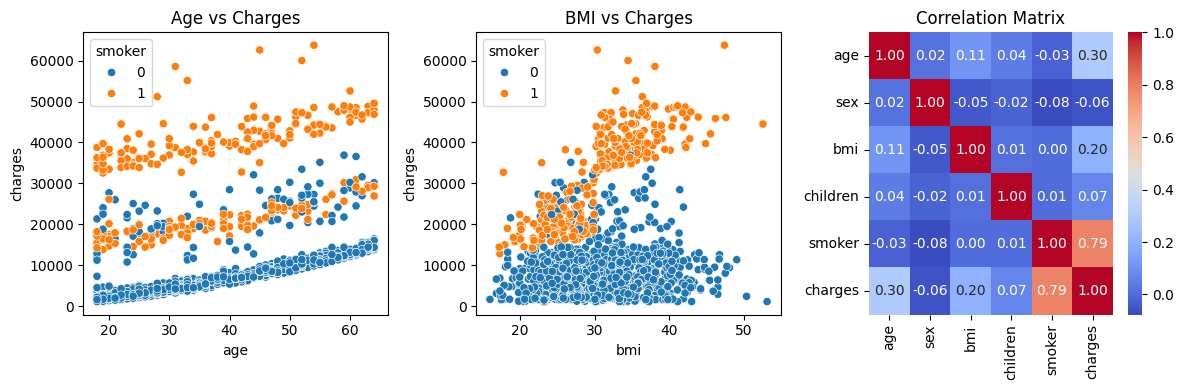

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Statistical Summary
print(df.describe())

# 2. Visualizations (Kam az kam 3 charts bananey hain)
plt.figure(figsize=(12, 4))

# Chart 1: Age vs Charges
plt.subplot(1, 3, 1)
sns.scatterplot(x='age', y='charges', data=df, hue='smoker')
plt.title('Age vs Charges')

# Chart 2: BMI vs Charges
plt.subplot(1, 3, 2)
sns.scatterplot(x='bmi', y='charges', data=df, hue='smoker')
plt.title('BMI vs Charges')

# Chart 3: Correlation Heatmap
plt.subplot(1, 3, 3)
# Note: Sirf numeric columns par correlation nikalein
sns.heatmap(df.select_dtypes(include=['number']).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')

plt.tight_layout()
plt.show()

In [6]:

X = df.drop("charges", axis=1)
y = df["charges"]

X = pd.get_dummies(X, drop_first=True)

print("X shape:", X.shape)
print("y shape:", y.shape)
X.head()

X shape: (1337, 8)
y shape: (1337,)


,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,False,False,True
1,18,0,33.770,1,0,False,True,False
2,28,0,33.000,3,0,False,True,False
3,33,0,22.705,0,0,True,False,False
4,32,0,28.880,0,0,True,False,False


In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1069, 8)
Testing set: (268, 8)


In [8]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [9]:
print("Model trained successfully!")
print("Intercept:", model.intercept_)

coef_df = pd.DataFrame({"Feature": X.columns, "Coefficient": model.coef_})
print(coef_df)

print("Training R2 score:", model.score(X_train, y_train))

Model trained successfully!
Intercept: -11194.194349936239
            Feature   Coefficient
0               age    248.210720
1               sex    101.542054
2               bmi    318.701441
3          children    533.009989
4            smoker  23077.764593
5  region_northwest   -391.761455
6  region_southeast   -838.919616
7  region_southwest   -659.139752
Training R2 score: 0.7299057809339075


In [10]:
y_pred = model.predict(X_test)

results = pd.DataFrame({"Actual": y_test.values, "Predicted": y_pred})
results.head(10)

,Actual,Predicted
0,8688.85885,8143.693884
1,5708.86700,5737.115683
2,11436.73815,14369.314876
3,38746.35510,31745.513636
4,4463.20510,8962.386657
5,9304.70190,13149.722353
6,38511.62830,30446.760679
7,2150.46900,1453.288813
8,7345.72660,10633.018402
9,10264.44210,11318.943794


In [11]:
y_pred = model.predict(X_test)

In [12]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE  :", round(mae, 2))
print("MSE  :", round(mse, 2))
print("RMSE :", round(rmse, 2))
print("R2 Score:", round(r2, 4))

MAE  : 4177.05
MSE  : 35478020.68
RMSE : 5956.34
R2 Score: 0.8069


In [14]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
})
comparison["Difference"] = comparison["Actual"] - comparison["Predicted"]
comparison.head(10)

,Actual,Predicted,Difference
0,8688.85885,8143.693884,545.164966
1,5708.86700,5737.115683,-28.248683
2,11436.73815,14369.314876,-2932.576726
3,38746.35510,31745.513636,7000.841464
4,4463.20510,8962.386657,-4499.181557
5,9304.70190,13149.722353,-3845.020453
6,38511.62830,30446.760679,8064.867621
7,2150.46900,1453.288813,697.180187
8,7345.72660,10633.018402,-3287.291802
9,10264.44210,11318.943794,-1054.501694


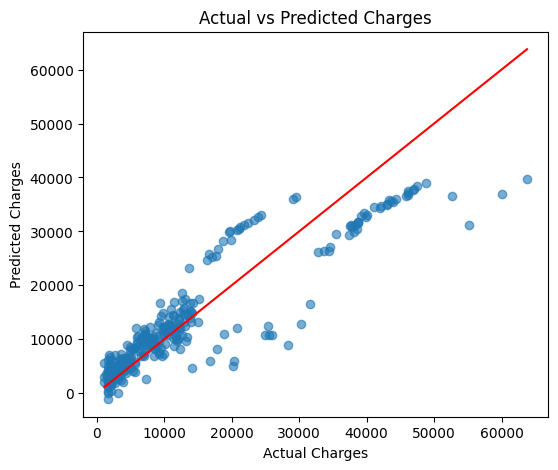

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Charges")
plt.show()

In [16]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# --- Input fields ---
age = widgets.IntSlider(value=30, min=18, max=64, description="Age:")
bmi = widgets.FloatText(value=25.0, description="BMI:")
children = widgets.IntSlider(value=0, min=0, max=5, description="Children:")
smoker = widgets.Dropdown(options=["no", "yes"], description="Smoker:")
sex = widgets.Dropdown(options=["male", "female"], description="Gender:")
region = widgets.Dropdown(
    options=["northeast", "northwest", "southeast", "southwest"],
    description="Region:"
)

button = widgets.Button(description="Predict Cost", button_style="success")
output = widgets.Output()

def predict_cost(_):
    row = {col: 0 for col in X.columns}
    row["age"] = age.value
    row["bmi"] = bmi.value
    row["children"] = children.value
    row["smoker"] = 1 if smoker.value == "yes" else 0
    row["sex"] = 1 if sex.value == "female" else 0   # matches your encoding (female = 1)

    region_col = "region_" + region.value
    if region_col in row:          # northeast is the dropped baseline, so it stays all zeros
        row[region_col] = 1

    input_df = pd.DataFrame([row])[X.columns]
    prediction = model.predict(input_df)[0]

    with output:
        clear_output()
        print(f"Estimated insurance cost: ${prediction:,.2f}")

button.on_click(predict_cost)

print("Medical Insurance Cost Prediction App")
display(age, bmi, children, smoker, sex, region, button, output)

Medical Insurance Cost Prediction App


IntSlider(value=30, description='Age:', max=64, min=18)

FloatText(value=25.0, description='BMI:')

IntSlider(value=0, description='Children:', max=5)

Dropdown(description='Smoker:', options=('no', 'yes'), value='no')

Dropdown(description='Gender:', options=('male', 'female'), value='male')

Dropdown(description='Region:', options=('northeast', 'northwest', 'southeast', 'southwest'), value='northeast…

Button(button_style='success', description='Predict Cost', style=ButtonStyle())

Output()

In [17]:
print("intercept =", model.intercept_)
for name, c in zip(X.columns, model.coef_):
    print(name, "=", c)

intercept = -11194.194349936239
age = 248.2107202247045
sex = 101.54205399029436
bmi = 318.70144095235065
children = 533.0099887986984
smoker = 23077.7645928681
region_northwest = -391.7614547836083
region_southeast = -838.9196157269689
region_southwest = -659.1397515529709


In [18]:
import joblib, sklearn
from google.colab import files

joblib.dump(model, "model.pkl")
joblib.dump(list(X.columns), "columns.pkl")
df.to_csv("insurance_cleaned.csv", index=False)
print("scikit-learn version:", sklearn.__version__)

files.download("model.pkl")
files.download("columns.pkl")
files.download("insurance_cleaned.csv")

scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import os, shutil, joblib, sklearn, numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from google.colab import files

os.makedirs("project/screenshots", exist_ok=True)

# model aur data
joblib.dump(model, "project/model.pkl")
joblib.dump(list(X.columns), "project/columns.pkl")
df.to_csv("project/insurance_cleaned.csv", index=False)

# metrics (README mein apne aap jayenge)
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

# requirements.txt
with open("project/requirements.txt", "w") as f:
    f.write(f"streamlit\npandas\njoblib\nscikit-learn=={sklearn.__version__}\n")

# app.py
app_code = '''import streamlit as st
import pandas as pd
import joblib

model = joblib.load("model.pkl")
columns = joblib.load("columns.pkl")

st.title("Medical Insurance Cost Predictor")
st.write("Enter your details to get an estimated yearly insurance cost.")

age = st.slider("Age", 18, 64, 30)
bmi = st.slider("BMI", 15.0, 50.0, 25.0)
children = st.selectbox("Children", [0, 1, 2, 3, 4, 5])
smoker = st.selectbox("Smoker", ["no", "yes"])
sex = st.selectbox("Gender", ["male", "female"])
region = st.selectbox("Region", ["northeast", "northwest", "southeast", "southwest"])

if st.button("Predict Cost"):
    row = {c: 0 for c in columns}
    row["age"] = age
    row["bmi"] = bmi
    row["children"] = children
    row["smoker"] = 1 if smoker == "yes" else 0
    row["sex"] = 1 if sex == "female" else 0
    if "region_" + region in row:
        row["region_" + region] = 1
    pred = model.predict(pd.DataFrame([row])[columns])[0]
    st.success(f"Estimated insurance cost: ${max(pred, 0):,.2f}")
'''
with open("project/app.py", "w") as f:
    f.write(app_code)

# README.md
readme = f"""# Medical Insurance Cost Prediction

## Problem
Predict the yearly medical insurance charge of a person from their age, BMI, number of children, smoking status, gender and region.

## Dataset
1,338 records, 7 columns (age, sex, bmi, children, smoker, region, charges). No missing values. One duplicate row was removed, leaving 1,337.

## Preprocessing
- Removed duplicates
- Encoded sex and smoker as 0/1
- One-hot encoded region
- 80/20 train-test split (random_state=42)

## Model
Multiple Linear Regression (scikit-learn).

## Evaluation (test set)
| Metric | Value |
|--------|-------|
| MAE | {mae:.2f} |
| MSE | {mse:.2f} |
| RMSE | {rmse:.2f} |
| R2 | {r2:.4f} |

## Key Findings
- Smoking is the biggest cost driver (correlation 0.79 with charges)
- Charges rise with age (0.30)
- BMI has a moderate effect (0.20)
- Gender and number of children have little impact

## Screenshots
Add your images from the screenshots folder here.

## Live App
PASTE YOUR DEPLOYED LINK HERE

## How to Run
pip install -r requirements.txt
streamlit run app.py

## Limitations
- A linear model cannot capture interactions (e.g. high BMI matters more for smokers)
- Trained on one public dataset, so it is an educational estimate, not a real insurance quote
- Predictions can be unrealistic at extreme inputs
"""
with open("project/README.md", "w") as f:
    f.write(readme)

shutil.make_archive("project", "zip", "project")
files.download("project.zip")
print("MAE:", round(mae, 2), "| MSE:", round(mse, 2), "| RMSE:", round(rmse, 2), "| R2:", round(r2, 4))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MAE: 4177.05 | MSE: 35478020.68 | RMSE: 5956.34 | R2: 0.8069
